# Graph for orbital period vs spin period (from spreadsheet data)

Text(0, 0.5, 'Spin Period (hr)')

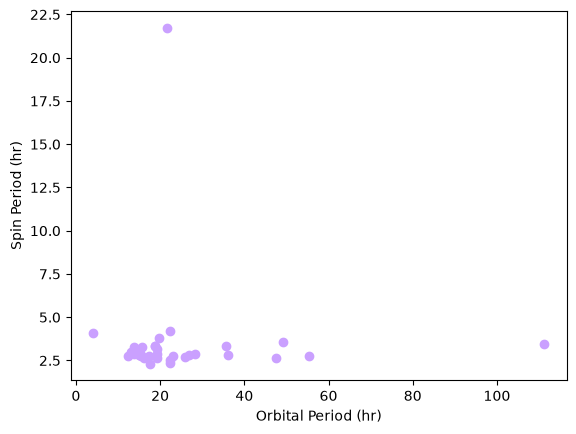

In [9]:
import pandas as pd 
import rocks 
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv('/Users/chloejgordon14/Downloads/sheet2 - Sheet2.csv')

x = df['period']
y = df['spin period']

plt.scatter(x,y, marker='o', color='xkcd:pastel purple')


plt.xlabel('Orbital Period (hr)')
plt.ylabel('Spin Period (hr)')


# Script for systems w/o and w/ spin values 
this script is also in my other notebook (missingspinperiodscript). I am also keeping it hear incase I need to use pieces of it.

In [43]:
import pandas as pd
import rocks

df = pd.read_csv('/Users/chloejgordon14/Downloads/spreadsheet2  - Sheet1-3.csv')

df['clean_name'] = [name for name, number in rocks.id(df['system_name'])]

print("Loading the BFT database")
bft = rocks.load_bft()

matched_df = pd.merge(
    df, 
    bft[['name', 'spins.period.value']], 
    left_on='clean_name', 
    right_on='name', 
    how='left'
)

print("\n--- Results Summary ---")
print(matched_df[['system_name', 'spins.period.value']])


no_spin_mask = matched_df['spins.period.value'].isna()

spin = matched_df[~no_spin_mask]
no_spin = matched_df[no_spin_mask]

print(f"Total Systems Analyzed: {len(matched_df)}")
print(f"Systems w/ known spin values: {len(spin)}")
print(f"Systems w/o known spin values: {len(no_spin)}")

WARNING  [rocks] Received empty or NaN identifier.

WARNING  [rocks] Received empty or NaN identifier.

WARNING  [rocks] Received empty or NaN identifier.

WARNING  [rocks] Received empty or NaN identifier.

WARNING  [rocks] Received empty or NaN identifier.

WARNING  [rocks] Received empty or NaN identifier.

ERROR    [rocks] Could not identify '/Users/chloejgordon14/Downloads/spreadsheet2  - Sheet1-2.csv''.

Loading the BFT database

--- Results Summary ---
     system_name spins.period.value
0    2005 EC_224            [3.758]
1      2013 XZ_8  [57.4848, 87.744]
2     1998 UN_15               None
3      1998 SQ_2     [3.681, 3.681]
4    2013 TC_146               None
..           ...                ...
402       Lundia           [15.418]
403    2000 RG79   [3.1665, 3.1665]
404      1990 OS               None
405       Huenna     [14.14, 14.14]
406         Emma          [6.89523]

[407 rows x 2 columns]
Total Systems Analyzed: 407
Systems w/ known spin values: 288
Systems w/o known spin values: 119


# Graph for Orbital Period vs Spin Period (bft data and MY data) WORKING!!!!

WARNING  [rocks] Received empty or NaN identifier.

WARNING  [rocks] Received empty or NaN identifier.

WARNING  [rocks] Received empty or NaN identifier.

WARNING  [rocks] Received empty or NaN identifier.

WARNING  [rocks] Received empty or NaN identifier.

WARNING  [rocks] Received empty or NaN identifier.

ERROR    [rocks] Could not identify 'queens'.

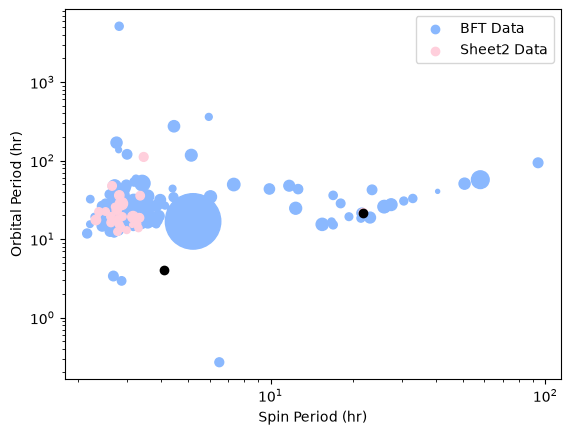

In [66]:
import pandas as pd
import rocks
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv('/Users/chloejgordon14/Downloads/UPDATED sheet2 - Sheet2-3.csv')

y = df['period']
x = df['spin period']


plt.xlabel('Orbital Period (hr)')
plt.ylabel('Spin Period (hr)')


df['clean_name'] = [name for name, number in rocks.id(df['name'])]

bft = rocks.load_bft()

matched_df = pd.merge( df,bft[['name', 'spins.period.value','orbital_elements.orbital_period.value', "diameter.value"]],left_on='clean_name', right_on='name',
how='left') 
sizes2 = matched_df["diameter.value"] * scaling_factor

matched_df=matched_df.dropna(subset='name_x')

plot_mask = ( ~pd.isnull(matched_df['spins.period.value']) & ~pd.isnull(matched_df['period'])& (matched_df['name_x'] != "Queen's"))

scaling_factor = 8
sizes = matched_df.loc[plot_mask, "diameter.value"] * scaling_factor


X = [x[0] for x in matched_df[plot_mask]['spins.period.value']]
Y = matched_df.loc[plot_mask, 'period']
b = (x==y)


plt.scatter(X, Y, s=sizes, color='xkcd:carolina blue')
plt.scatter(x,y, s=sizes2, marker='o', color='xkcd:pale pink')
plt.scatter(x[b],y[b], marker='o', color='k')


plt.scatter([], [], color='xkcd:carolina blue', label='BFT Data',)
plt.scatter([],[], marker='o', color='xkcd:pale pink', label='Sheet2 Data')

plt.loglog()

plt.ylabel('Orbital Period (hr)')
plt.xlabel('Spin Period (hr)')
plt.legend()
plt.show()




In [67]:
b

0      False
1      False
2      False
3      False
4      False
       ...  
404    False
405    False
406    False
407    False
408    False
Length: 409, dtype: bool

In [44]:
print(matched_df['period'].head(10))


0      NaN
1      NaN
2    26.45
3      NaN
4      NaN
5      NaN
6      NaN
7      NaN
8    23.17
9      NaN
Name: period, dtype: float64


In [13]:
bft["spins.period.value"][0:50]


0             None
1             None
2             None
3             None
4             None
5             None
6             None
7        [4.55053]
8             None
9          [5.924]
10            None
11            None
12            None
13            None
14            None
15            None
16            None
17            None
18            None
19            None
20        [2.6645]
21            None
22            None
23    [4.78, 4.78]
24            None
25            None
26            None
27            None
28          [3.23]
29            None
30            None
31         [6.024]
32            None
33            None
34            None
35            None
36            None
37            None
38            None
39            None
40            None
41            None
42            None
43            None
44            None
45          [8.59]
46            None
47            None
48         [11.29]
49        [21.216]
Name: spins.period.value, dtype: object

In [130]:
plot_mask = ~pd.isnull(matched_df['spins.period.value'])

In [131]:
matched_df[plot_mask]['spins.period.value']

1           [5.508, nan]
2                [3.758]
3      [57.4848, 87.744]
5         [3.681, 3.681]
7                [263.8]
             ...        
403               [25.9]
404             [15.418]
405     [3.1665, 3.1665]
407       [14.14, 14.14]
408            [6.89523]
Name: spins.period.value, Length: 289, dtype: object

In [99]:
[x[0] if x is not None else '' for x in matched_df['spins.period.value'][130:140]]

TypeError: 'float' object is not subscriptable

In [100]:
matched_df[['num', 'name_x', 'spins.period.value']][130:140]

,num,name_x,spins.period.value
132,10424,Gaillard,None
133,6086,Vrchlicky,"[2.767405, 2.767405]"
134,NaN,2009 YK32,None
135,534625,2014 UQ224,None
136,82256,2001 KM8,[12.632]
138,18301,Konyukhov,"[2.6667, 2.6667]"
139,7355,Bottke,"[2.636, 2.636]"
140,5457,Queens,NaN
141,NaN,2023 QE6,None
142,152830,Dinkinesh,[52.67]


In [76]:
matched_df.loc[42]

num                                      NaN
name_x                                   NaN
date                                     NaN
PI                                       NaN
period                                   NaN
sig_period                               NaN
ds_dp                                    NaN
ds_dp_LL                                 NaN
sig_ds_dp                                NaN
spin period                              NaN
sig_spin period                          NaN
CBET                                     NaN
notes                                    NaN
Unnamed: 13                              NaN
Unnamed: 14                              NaN
clean_name                               NaN
name_y                                   NaN
spins.period.value                       NaN
orbital_elements.orbital_period.value    NaN
Name: 42, dtype: object